In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [267]:
import matplotlib.pyplot as plt
from kneed import KneeLocator
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

In [343]:
tracks = pd.read_json('tracks.jsonl', lines=True)
tracks.sample()

,id,name,popularity,duration_ms,explicit,id_artist,release_date,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
10754,3tZs3nVjySLbL320lP4mvs,Focus,68,200133,0,3Y7RZ31TRPVadSFVy1o8os,2017-10-20,0.415,0.313,1,-12.945,0.0561,0.255,0.000014,0.117,0.0875,84.953


In [229]:
features = ['danceability', 'energy', 'speechiness', \
            'instrumentalness', 'liveness']
numeric_features = tracks.select_dtypes(include=['int64', 'float64']).columns

In [346]:
import numpy as np
scaler = StandardScaler()
for feature in features:
    tracks[feature] = scaler.fit_transform(tracks[feature].to_frame())


,popularity,duration_ms,explicit,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,55,201467,0,0.466992,-1.293191,0,-14.141,-0.147948,0.5860,-0.263179,0.826836,0.7130,88.973
1,54,198000,0,-2.496578,-2.371576,2,-17.842,-0.460325,0.9470,-0.263119,0.761337,0.1340,91.783
2,55,199000,0,-1.921557,-2.697954,1,-19.569,-0.517426,0.9840,-0.260837,-0.221159,0.1690,128.600
3,54,163000,0,-0.240726,-1.493599,9,-11.093,-0.369635,0.8400,-0.263169,3.542097,0.5900,126.974
4,53,186173,0,-2.540810,-2.831560,1,-22.411,-0.540938,0.9500,1.542815,-0.244977,0.1000,90.150
...,...,...,...,...,...,...,...,...,...,...,...,...,...
22407,65,214987,0,-0.392380,-0.004855,2,-7.370,-0.347242,0.1680,-0.263179,-0.506976,0.5310,79.770
22408,70,198799,0,-0.670412,-0.892375,2,-8.524,-0.417779,0.8450,-0.263179,-0.465294,0.3500,51.414
22409,63,195868,0,-0.133305,0.438905,2,-5.080,-0.121076,0.0119,-0.263179,-0.078251,0.4950,155.984
22410,67,202355,0,-0.057478,-0.978264,0,-5.662,-0.119957,0.6180,-0.263179,-0.495067,0.3420,149.447


In [333]:
features_values = tracks[features]

### Ustalanie właściwej ilość klastrów

## Cel

Chemy uzyskać jak największą spójność klastrów

#### Elbow method

In [364]:
kmeans_kwargs = {
    "init": "random",
    "n_init": 10,
    "max_iter": 1000,
    "random_state": 42,
}

# A list holds the SSE values for each k
sse = []
range_clusters = range(3, 40)
for k in range_clusters:
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(features_values)
    sse.append(kmeans.inertia_)

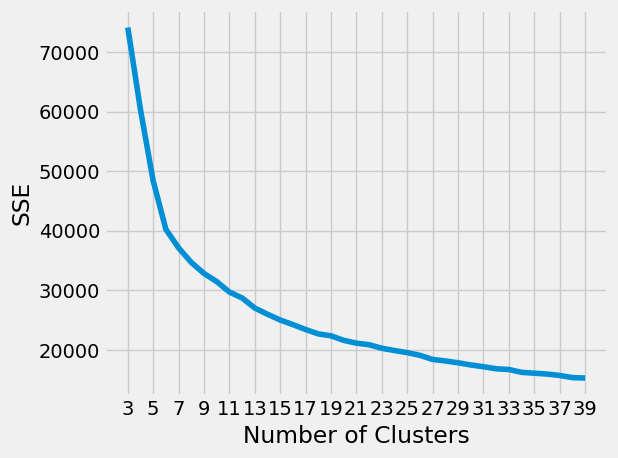

In [365]:
plt.style.use("fivethirtyeight")
plt.plot(range_clusters, sse)
plt.xticks(range_clusters[::2])
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.tight_layout()
plt.show()

#### Wnioski

6 - to "elbow point"

#### Silhouette Coefficeint method

In [366]:
# A list holds the silhouette coefficients for each k
silhouette_coefficients = []
range_clusters = range(3, 40)

# Notice you start at 2 clusters for silhouette coefficient
for k in range_clusters:
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(features_values)
    score = silhouette_score(features_values, kmeans.labels_)
    silhouette_coefficients.append(score)

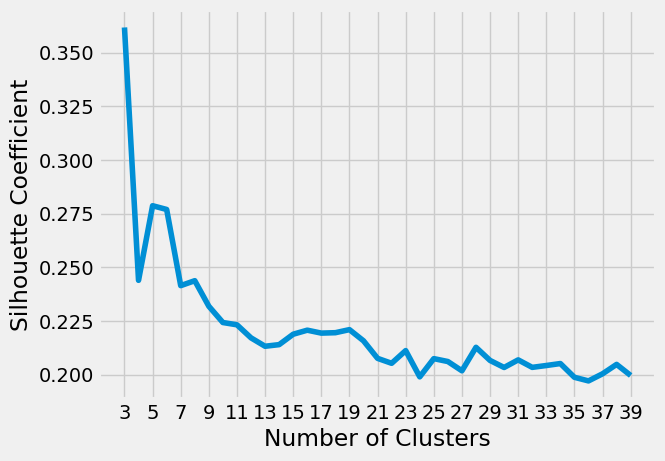

In [367]:
plt.style.use("fivethirtyeight")
plt.plot(range_clusters, silhouette_coefficients)
plt.xticks(range_clusters[::2])
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Coefficient")
plt.show()

#### Wnioski

Przy liczbie klastrów równej 6 SC ma wartość ~0.3, oznacza to, że udało się częściowo opdzielić zbiór na klastry, ale nie są one do końca spójne.

## Wczytywanie sesji

In [1]:
import pandas as pd
import json

filename = 'sessions6.jsonl'

cleaned_lines = []
with open(filename, 'r', encoding='utf-8') as file:
    for line_number, line in enumerate(file, start=1):
        line = line.strip()
        if line:
            try:
                json_obj = json.loads(line)
                cleaned_lines.append(json_obj)
            except json.JSONDecodeError as e:
                print(f"Error parsing JSON at line {line_number}: {e}")
                break

sessions = pd.DataFrame(cleaned_lines)


In [2]:
sessions = sessions[sessions['event_type'] == 'play']

In [3]:
tracks.loc[:, 'coherence'] = 0


NameError: name 'tracks' is not defined

## Wyliczanie parametru choerence dla określonej liczby klastrów

In [371]:
NUBMER_OF_CLUSTERS = 6

In [372]:
kmeans = KMeans(
    init="random",
    n_clusters=NUBMER_OF_CLUSTERS,
    n_init=1000,
    max_iter=100000,
    random_state=42
)

In [373]:
features_values = tracks[features]

In [374]:
kmeans.fit(features_values)

KMeans(init='random', max_iter=100000, n_clusters=6, n_init=1000,
       random_state=42)

In [375]:
kmeans.labels_

array([1, 1, 1, ..., 0, 1, 1], dtype=int32)

In [377]:
tracks['cluster'] = kmeans.labels_


## Wyliczanie współczynnika dla każdej piosenki względem sesji

Ile razy dana piosenka znalazła się w jednej sesji z innymi piosenkami zakwalifikowanymi do tej samej grupy gatunkowej.
Nie bierzemy pod uwagę piosenek przewiniętych "skip".

In [378]:
def collect_track_ids(track_id, tracks_in_session, tracks_in_session_collected: set):
    if track_id in tracks_in_session:
        tracks_in_session_collected.add(track_id)

In [379]:
sessions_ids = set(sessions['session_id'].tolist())
for session_id in sessions_ids:
    tracks_in_session = sessions[sessions['session_id'] == session_id]['track_id'].tolist()

    tracks_in_session_collected = set()
    tracks['id'].apply(lambda x: collect_track_ids(x, tracks_in_session, tracks_in_session_collected))

    if len(tracks_in_session) > 1:
        for track_id in tracks_in_session_collected:
            tracks.loc[tracks['id'] == track_id, 'coherence'] += 1

In [389]:
tracks.to_json(f'annotated_kmeans.json', orient='records', lines=True)

In [ ]:
# for genre in genres_to_filter:
#     divided_songs[genre] = pd.read_json(f'annotaded_tracks/{genre}_annotated.json', orient='records', lines=True)

In [384]:
# tracks[tracks['cluster'] == 4]['coherence'].apply(lambda x: print(x) if x > 1 else print('', end=''))
len(tracks[tracks['cluster'] == 0])
tracks[tracks['cluster'] == 0]['speechiness'].apply(lambda x: print(x))

-0.3013370300728111
-0.2957388764401168
-0.43681234798401225
-0.42225714853900714
-0.5252631753805815
-0.5241435446540428
-0.02590787134425327
-0.22520214066816902
-0.5722876658952134
-0.29909776861973336
-0.5118276066621154
-0.3640363507589868
-0.0236686098911755
-0.03710417860964181
-0.5129472373886542
-0.32708853678320465
-0.26438921609702887
-0.5689287737155968
-0.5465361591848199
-0.43457308653093457
-0.5700484044421358
-0.5566128357236695
-0.27894441554203403
-0.1692206043412265
-0.4110608412736186
-0.5510146820909753
-0.5039901915763434
-0.36851487366514224
0.22488941140044977
0.3928340203812777
-0.5946802804259905
-0.4860760999517218
-0.24759475519894616
-0.5577324664502084
-0.18041691160661502
-0.37747191947745307
0.10844781584040902
-0.6237906793160006
-0.5857232346136797
-0.5532539435440529
0.2024967968696727
-0.4983920379436491
-0.6327477251283115
-0.08972682275696783
-0.15578503562276017
-0.5118276066621154
-0.6125943720506121
-0.47487979268633324
-0.5465361591848199
-0.38

11       None
63       None
66       None
67       None
68       None
         ... 
22385    None
22389    None
22398    None
22407    None
22409    None
Name: speechiness, Length: 5713, dtype: object

In [387]:
numeric_features = tracks[tracks['cluster'] == 4].select_dtypes(include=['int64', 'float64']).columns
covariance_matrix = tracks[tracks['cluster'] == 0][numeric_features].corr()
covariance_matrix.style.background_gradient(cmap='coolwarm', axis=None, vmin=-1, vmax=1).format(precision=3)

,popularity,duration_ms,explicit,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,coherence
popularity,1.000,-0.072,0.045,0.079,-0.084,-0.008,0.039,-0.023,0.018,-0.067,-0.024,-0.007,-0.019,0.259
duration_ms,-0.072,1.000,-0.019,-0.220,-0.098,-0.010,-0.168,-0.084,-0.076,0.144,-0.055,-0.273,-0.061,-0.051
explicit,0.045,-0.019,1.000,-0.070,0.051,0.013,0.031,0.249,-0.064,0.028,0.013,-0.121,-0.013,0.016
danceability,0.079,-0.220,-0.070,1.000,0.025,-0.000,0.074,-0.161,0.104,-0.094,0.039,0.382,-0.213,0.015
energy,-0.084,-0.098,0.051,0.025,1.000,0.022,0.462,0.299,-0.375,0.045,0.051,0.185,0.082,-0.008
key,-0.008,-0.010,0.013,-0.000,0.022,1.000,0.003,0.034,-0.033,0.014,-0.009,0.005,-0.005,0.019
loudness,0.039,-0.168,0.031,0.074,0.462,0.003,1.000,0.142,-0.154,-0.158,0.047,-0.012,0.056,0.018
speechiness,-0.023,-0.084,0.249,-0.161,0.299,0.034,0.142,1.000,-0.014,-0.021,0.064,-0.069,0.140,0.013
acousticness,0.018,-0.076,-0.064,0.104,-0.375,-0.033,-0.154,-0.014,1.000,-0.066,0.017,0.127,-0.018,-0.001
instrumentalness,-0.067,0.144,0.028,-0.094,0.045,0.014,-0.158,-0.021,-0.066,1.000,-0.018,-0.037,-0.003,-0.023


In [388]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np

columns = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness',
          'speechiness', 'acousticness', 'liveness', 'valence', 'tempo', 'genre']
mutual_info = pd.DataFrame(columns=columns)
for i in range(NUBMER_OF_CLUSTERS):
    new_data = mutual_info_regression(tracks[tracks['cluster'] == i].loc[:, columns[:-1]], tracks[tracks['cluster'] == i]['coherence'])
    new_data = np.append(new_data, i)
    new_data = new_data.reshape(1, len(new_data))
    new_rows_df = pd.DataFrame(new_data, columns=mutual_info.columns, )
    mutual_info = pd.concat([mutual_info, new_rows_df], ignore_index=True)
mutual_info

/tmp/ipykernel_90941/4069277374.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  mutual_info = pd.concat([mutual_info, new_rows_df], ignore_index=True)


,popularity,duration_ms,danceability,energy,loudness,speechiness,acousticness,liveness,valence,tempo,genre
0,0.036601,0.000000,0.000000,0.000573,0.000000,0.000000,0.0,0.000765,0.016980,0.000000,0.0
1,0.017945,0.000000,0.003888,0.007311,0.003676,0.011037,0.0,0.007576,0.000000,0.012074,1.0
2,0.047421,0.000084,0.000000,0.059112,0.002490,0.018967,0.0,0.013746,0.000000,0.041357,2.0
3,0.032747,0.008526,0.028517,0.000000,0.003384,0.000000,0.0,0.000000,0.013660,0.001663,3.0
4,0.048209,0.000000,0.011421,0.006959,0.000000,0.018218,0.0,0.006298,0.006234,0.005784,4.0
5,0.043826,0.038942,0.017391,0.007520,0.027292,0.000000,0.0,0.032072,0.000000,0.000000,5.0
